# Lab: Amazon Product Data

step 1: get data

In [2]:
%pip install kagglehub
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Note: you may need to restart the kernel to use updated packages.
Path to dataset files: /Users/isishassan/.cache/kagglehub/datasets/asaniczka/uk-optimal-product-price-prediction/versions/3


step 2: import the libraries i need

In [3]:
import pandas as pd
import matplotlib.pyplot as plt # viz
import seaborn as sns # better viz
import numpy as np # numerical python
import os 

In [4]:
data = pd.read_csv(r"/Users/isishassan/.cache/kagglehub/datasets/asaniczka/uk-optimal-product-price-prediction/versions/3/amz_uk_price_prediction_dataset.csv")

step 3: explore the data

In [5]:
data.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


Data Available:

- uid: ?, probably some type of index, technically should be covered by ASIN though
- ASIN: unique product identifier - check for nulls and duplicates, would be very bad
- title: product name - check for duplicates, acceptable
- stars: rating x out of 5
- reviews: no. of reviews
- price: retail price (assumed, since no other price given)
- is BestSeller: boolean - check if products with 0 order last month included. points to bad data
- category

describe to pull up basic calculations

In [5]:
round(data.describe().T,2)

,count,mean,std,min,25%,50%,75%,max
uid,2443651.0,1370545.35,816056.17,1.0,658921.50,1349029.00,2060685.50,2828593.0
stars,2443651.0,2.15,2.19,0.0,0.00,0.00,4.40,5.0
reviews,2443651.0,480.63,5944.12,0.0,0.00,0.00,59.00,1356658.0
price,2443651.0,89.24,345.61,0.0,9.99,19.09,45.99,100000.0
boughtInLastMonth,2443651.0,25.90,240.48,0.0,0.00,0.00,0.00,50000.0


Observations:
- uid: ignore
- stars: avg rating is really bad. since the min is "0", 0 actually means no rating, so this is distorting this avg.
- price: very high range. min being 0 means there are un-priced products

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [7]:
data.shape

(2443651, 9)

Checking for N/As and " "

In [8]:
data.isna().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [9]:
data.eq(" ").sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

Note: Based on the fact that there's a min price of 0, there are technically no NA values, but practically there is missing data

Checking for Duplicates

In [10]:
data.duplicated().sum()

np.int64(0)

## Part 1: Understanding Product Categories
Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

Frequency Tables:

Generate a frequency table for the product category.
Which are the top 5 most listed product categories?

In [107]:
#code here

frequency_table_category = data.category.value_counts()                                 #getting my value counts per category

top_5_categories = frequency_table_category.sort_values(ascending=False).head(5)        #using sort_values and head() function to get top 5 

top_5_categories           #result


#len(frequency_table_category)                                                          #296 categories overall

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

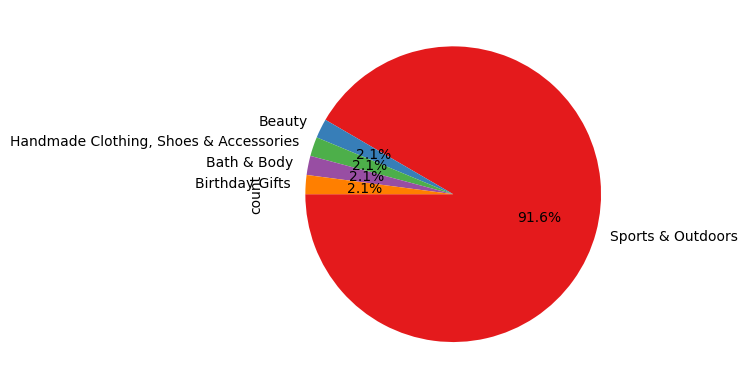

In [ ]:
#way too many categories, i need a subset (although using a pie chart for a subset is very questionable).
#for a pie chart, more than 5 values is questionable anyway, so i can continue with my top_5

top_5_categories.plot.pie(autopct='%1.1f%%' ,startangle=180, colors=sns.color_palette('Set1'))
plt.show()

Observation:Sports & Outdoor clearly dominates the top 5 categories

Note: IRL, I would never pick a pie chart for this data. 

## Part 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

Measures of Centrality:

Calculate the mean, median, and mode for the price of products.
What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [47]:
data.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [48]:
#avg price
data_mean = data['price'].mean()

display(data_mean)

np.float64(89.24380943923661)

In [49]:
#median price
data['price'].median()

19.09

In [50]:
#mode
data['price'].mode()

0    9.99
Name: price, dtype: float64

Observation: The average price is much higher than the median, meaning there are some very high-priced outliers. The most-frequent price is 9.99

Measures of Dispersion:

Determine the variance, standard deviation, range, and interquartile range for product price.
How varied are the product prices? Are there any indicators of a significant spread in prices?

In [51]:
#just to double check that i have things correct
round(data.describe().T,2)

,count,mean,std,min,25%,50%,75%,max
uid,2443651.0,1370545.35,816056.17,1.0,658921.50,1349029.00,2060685.50,2828593.0
stars,2443651.0,2.15,2.19,0.0,0.00,0.00,4.40,5.0
reviews,2443651.0,480.63,5944.12,0.0,0.00,0.00,59.00,1356658.0
price,2443651.0,89.24,345.61,0.0,9.99,19.09,45.99,100000.0
boughtInLastMonth,2443651.0,25.90,240.48,0.0,0.00,0.00,0.00,50000.0


In [108]:
#standard deviation
data_std = data['price'].std()


In [53]:
#interpreting std, in relation to the mean
data_std / data_mean


np.float64(3.872636812851841)

Observation: very large spread in product prices since 

In [54]:
#variance
data['price'].var()

119445.4853225653

In [55]:
#range                          max price - min price
range = data['price'].max() - data['price'].min()

range

100000.0

In [56]:
#interquartile range
#1 get quartiles                    
q1 = np.percentile(data['price'], 25)
q2 = np.percentile(data['price'], 50)
q3 = np.percentile(data['price'], 75)
q4 = np.percentile(data['price'], 100)

#2calculate the interquartile range, by substracting q1 from q4 
interquartile_range = q3-q1                             #iqr measures spread in the middle, i.e. excluding extremes in Q1 and Q4


print(f"Quartile 1 price = {q1}")
print(f"Quartile 3 price = {q3}")
print(f"The interquartile_range ={interquartile_range}")

Quartile 1 price = 9.99
Quartile 3 price = 45.99
The interquartile_range =36.0


Visualisation:
Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

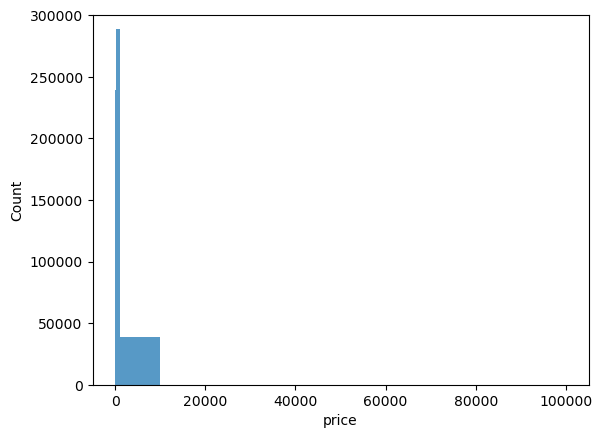

In [126]:
bins = [0,1, 5,10,20,30,40,50, 100, 1000, 10000, 20000,50000,100000]

sns.histplot(x=data.price,bins=bins)
plt.ylim(0, 300000)
plt.show()

Observation: Since we have a very large range of prices, but the vast majority of products is priced below 100, the data is concentrated in the bottom left corner, making a basic histogram not the best graph of choice

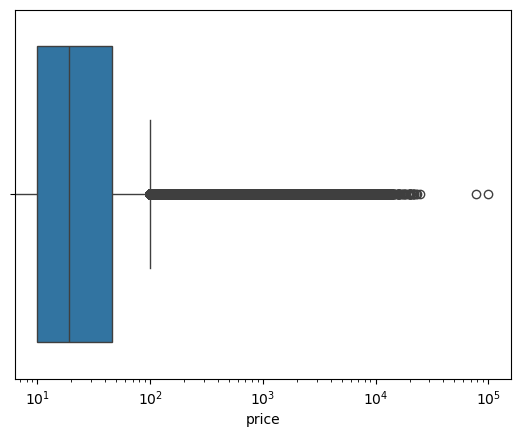

In [127]:
sns.boxplot(x=data["price"])
plt.xscale("log")  # compress high values
plt.show()

The box plot clearly shows that there are very few outliers > 20000, and that prices are concentrated at the lower end of the price-axis

## Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

Measures of Centrality:

Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend?

In [71]:
data['stars'].mean()

np.float64(2.152836472966066)

In [72]:
data['stars'].median()

0.0

In [73]:
data['stars'].mode()

0    0.0
Name: stars, dtype: float64

Observation: Both median and mode are 0 stars. This implies that the most common rating is 0 stars, which is not realistic. To me that means that 0 stars actually means not-rated. In turn that means that the mean (and all other calculatoions) should be calculated off a subset that only consists or products with a rating. I will work under that assumption.

In [77]:

#step 1: create a subset consisting of rated products only
data_rated = data[data["stars"] > 0]

round(data_rated.describe().T,2)

,count,mean,std,min,25%,50%,75%,max
uid,1218010.0,1397793.60,842052.54,1.0,690584.25,1390506.50,2126019.75,2828593.0
stars,1218010.0,4.32,0.56,1.0,4.10,4.40,4.60,5.0
reviews,1218010.0,964.27,8391.68,1.0,9.00,60.00,360.00,1356658.0
price,1218010.0,45.31,128.81,0.0,8.99,16.97,34.85,19990.0
boughtInLastMonth,1218010.0,51.82,338.44,0.0,0.00,0.00,0.00,50000.0


In [89]:
mean = data_rated['stars'].mean()

mean

np.float64(4.319160762226911)

In [79]:
data_rated['stars'].median()

4.4

In [80]:
data_rated['stars'].mode()

0    4.5
Name: stars, dtype: float64

Observation: The most common rating (mode) is higher than the median and the mode.

Measures of Dispersion:

Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?

In [83]:
#standard deviation
std = data_rated['stars'].std()

std

0.5552867504614637

In [84]:
#variance
var = data_rated['stars'].var()

var

0.30834337523805183

In [86]:
#iqr

q1 = np.percentile(data_rated['stars'],25)
q3 = np.percentile(data_rated['stars'],75)

iqr = q3-q1

iqr

np.float64(0.5)

In [90]:
std / mean

np.float64(0.12856357543291907)

Observation: There's not a lot of variation in customer feedback, which makes sense since star ratings have limited values, and can only range from 1 to 5.

Shape of the Distribution:

Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values?

In [91]:
#skew
data_rated["stars"].skew()  

np.float64(-2.379568112212799)

We have a negative skew, since our average is below the median (and below the mode) and we're leaning towards lower values

In [99]:
#kurtosis                               #i have no idea what that means

data_rated['stars'].kurt()

np.float64(9.78193769066435)

kurtosis is very high, implying that ratings are concentrated on the high end of our spectrum (1 to 5 stars), but there are outliers of very bad ratings.

Visualisation: Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

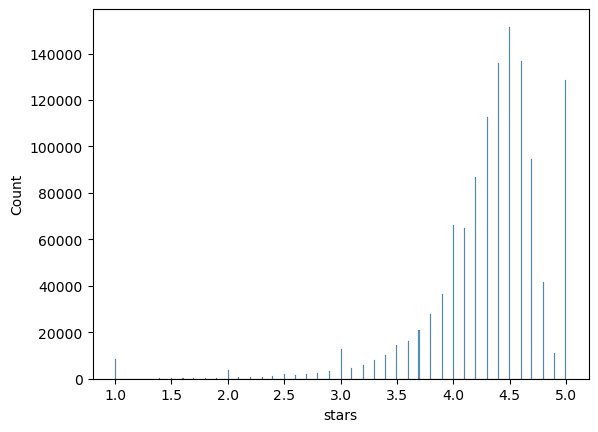

In [100]:
sns.histplot(x=data_rated.stars);
plt.show()

The graph shows that reviews are concentrated on the higher end, with an avg 4.5 star rating being the most common. noteworthy is also a relatively high number of products with a 1 star rating - implying that there are some products that are disliked by all customers and that should probably be removed from the store.

## Report

### 1. Categories

*Observations*
 
The Sports & Outdoor category selection heavily dominated the catalog, representing 91.6% of the top five categories.

*Next Step Recommendation*

Reduce no. of categories, or create hierarchical categories to simplify analysis and decision making. E.g. the now dominant "Sports & Outdoor" category can be broken up; and Skin Care and Make-Up are currently separate categories from Beauty, although they former should be subcategories of the latter.

### 2. Prices

*Observations*

The vast majority of prices are at the lower end, with the average price being 89, the median 19 and the mode 9.99. This view is further distorted by a few extreme outliers above 20,000. In addition, there are products with a price of 0.

*Next Step Recommendation*

Regularly review outliers for pricing errors. Products with price = 0 should not be online, products with extremely high prices to be reviewed by pricing team.


### 3. Ratings

*Observations*
Considering rated products only, the average product rating is 4.32, below the median rating of 4.4. This means that most customers really like our products, but since negative ratings are often extreme, they skew the average.

*Next Step Recommendation*

Review 1 star products for quality.

In [109]:
data["category"].nunique  

<bound method IndexOpsMixin.nunique of 0              Hi-Fi Speakers
1              Hi-Fi Speakers
2              Hi-Fi Speakers
3              Hi-Fi Speakers
4              Hi-Fi Speakers
                  ...        
2443646    Motorbike Clothing
2443647    Motorbike Clothing
2443648    Motorbike Clothing
2443649    Motorbike Clothing
2443650    Motorbike Clothing
Name: category, Length: 2443651, dtype: object>